## Redefine mis-labelled train/test points
& create new geojason with it.



In [5]:
import geemap
import ee

#ee.Authenticate(force=True)
ee.Initialize(project='ee-sbouchiba')


### **Import input data**

In [6]:
## Import Geneva footprint
import geopandas as gpd
import json

city_names = ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
train_city = 'allcity'

allcity_roi_path = './input/footprints/study_areas.geojson'
allcity_roi_gpd = gpd.read_file(allcity_roi_path)
allcity_roi_gpd = allcity_roi_gpd.to_crs("EPSG:4326") # convert projected CRS into WGS84 longitude/latitude.

geom = {
    "geneva":   allcity_roi_gpd.geometry.iloc[0],
    "lausanne": allcity_roi_gpd.geometry.iloc[1],
    "bern":     allcity_roi_gpd.geometry.iloc[2],
    "basel":    allcity_roi_gpd.geometry.iloc[3],
    "zurich":   allcity_roi_gpd.geometry.iloc[4],
    "lugano":   allcity_roi_gpd.geometry.iloc[5],
    "allcity":  allcity_roi_gpd.union_all(),
}

roi = ee.Geometry(geom['allcity'].__geo_interface__)
roi_fc = ee.FeatureCollection([ee.Feature(roi)])


In [32]:
## Import train/test datasets

#train_polygons = ee.FeatureCollection('./input/geneva_2022_training_polygons.geojson');
#test_polygons  = ee.FeatureCollection('./input/geneva_2022_testing_polygons.geojson');
import geopandas as gpd
import pandas as pd

train_city = 'geneva'

## Collect training samples
if train_city=='allcity':
    centroid_gdfs = []
    polygon_gdfs  = []
    for city in city_names:
        centroid_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_centroids.geojson"
        )
        polygon_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_polygons.geojson"
        )
    
        # Optional: keep track of origin city
        centroid_gdf["city"] = city
        polygon_gdf["city"] = city
    
        centroid_gdfs.append(centroid_gdf)
        polygon_gdfs.append(polygon_gdf)
    
    # Merge all cities
    train_centroids_gdf = gpd.GeoDataFrame(
        pd.concat(centroid_gdfs, ignore_index=True),
        crs=centroid_gdfs[0].crs
    )
    
    train_polygons_gdf = gpd.GeoDataFrame(
        pd.concat(polygon_gdfs, ignore_index=True),
        crs=polygon_gdfs[0].crs
    )

else:
    train_centroids_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_centroids.geojson')
    train_polygons_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_polygons.geojson')
    train_centroids_gdf['city'] = train_city
    train_polygons_gdf['city'] = train_city

#print(train_centroids_gdf.columns)

# Remove signature class for test datasets
train_centroids_gdf = (train_centroids_gdf[train_centroids_gdf["macroclass_id"] != 1].copy())
train_polygons_gdf = (train_polygons_gdf[train_polygons_gdf["macroclass_id"] != 1].copy())

# Re-map: define new class mapping that is simpler to handle
class_mapping = {
    2: 1,   # Compact MR
    5: 2,   # Open MR
    6: 3,   # Open LR
    8: 4,   # Large LR
    11: 5,  # Dense Trees
    14: 6,  # Low plants
    15: 7,  # Bare Rock/Paved
    17: 8   # Water
}

# Some data re-arrangement
train_centroids_gdf["LCZ_class"] = (train_centroids_gdf["macroclass_id"].map(class_mapping))
train_polygons_gdf["LCZ_class"]  = (train_polygons_gdf["macroclass_id"].map(class_mapping))
# Some monitoring
#print(train_centroids_gdf.columns.tolist())
#print(train_centroids_gdf["LCZ_class"].value_counts().sort_index())
#print(test_centroids_gdf["LCZ_class"].value_counts().sort_index())
#print(train_centroids_gdf.shape)
#print(test_centroids_gdf.shape)

# Convert to EE datasets
train_centroids = geemap.geopandas_to_ee(train_centroids_gdf)
train_polygons  = geemap.geopandas_to_ee(train_polygons_gdf)

train_centroids = train_centroids.map(lambda f: f.set('point_id', f.get('system:index')))

In [33]:
import geopandas as gpd
import pandas as pd

test_city = 'geneva'

test_centroids_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_centroids.geojson")
test_polygons_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_polygons.geojson")

test_centroids_gdf["LCZ_class"]  = (test_centroids_gdf["macroclass"].map(class_mapping))
test_polygons_gdf["LCZ_class"]   = (test_polygons_gdf["macroclass"].map(class_mapping))
test_centroids_gdf['city'] = test_city
test_polygons_gdf['city'] = test_city

test_centroids  = geemap.geopandas_to_ee(test_centroids_gdf)
test_polygons   = geemap.geopandas_to_ee(test_polygons_gdf)

# define point_id
test_centroids = test_centroids.map(lambda f: f.set('point_id', f.get('system:index')))

In [51]:
test_centroids_gdf = gpd.read_file(f"./input/samples/original/{city}_2022_testing_centroids.geojson")

In [52]:
test_centroids_gdf

,geometry


In [54]:
# Add Point ID and city :)


def assign_point_id(gdf):
    gdf = gdf.reset_index(drop=True)
    gdf["point_id"] = gdf["city"] + "_" + gdf.groupby("city").cumcount().astype(str)
    return gdf

def assign_global_id(*gdfs, col="id_num"):
    offset = 0
    for gdf in gdfs:
        gdf[col] = range(offset, offset + len(gdf))
        offset += len(gdf)
    return gdfs

city_names = ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
for city in city_names:
    train_centroids_gdf = gpd.read_file(f'./input/samples/original/{city}_2022_training_centroids.geojson')
    train_polygons_gdf = gpd.read_file(f'./input/samples/original/{city}_2022_training_polygons.geojson')

    test_centroids_gdf = gpd.read_file(f"./input/samples/original/{city}_2022_testing_centroids.geojson")
    test_polygons_gdf = gpd.read_file(f"./input/samples/original/{city}_2022_testing_polygons.geojson")
    
    train_centroids_gdf['city'] = city
    train_polygons_gdf['city'] = city

    test_centroids_gdf['city'] = city
    test_polygons_gdf['city'] = city

    train_centroids_gdf = (train_centroids_gdf[train_centroids_gdf["macroclass_id"] != 1].copy())
    train_polygons_gdf = (train_polygons_gdf[train_polygons_gdf["macroclass_id"] != 1].copy())
    
    class_mapping = {
    2: 1,   # Compact MR
    5: 2,   # Open MR
    6: 3,   # Open LR
    8: 4,   # Large LR
    11: 5,  # Dense Trees
    14: 6,  # Low plants
    15: 7,  # Bare Rock/Paved
    17: 8   # Water
    }

    # Some data re-arrangement
    train_centroids_gdf["LCZ_class"] = (train_centroids_gdf["macroclass_id"].map(class_mapping))
    train_polygons_gdf["LCZ_class"]  = (train_polygons_gdf["macroclass_id"].map(class_mapping))

    test_centroids_gdf["LCZ_class"]  = (test_centroids_gdf["macroclass"].map(class_mapping))
    test_polygons_gdf["LCZ_class"]   = (test_polygons_gdf["macroclass"].map(class_mapping))


    train_centroids_gdf = assign_point_id(train_centroids_gdf)
    test_centroids_gdf  = assign_point_id(test_centroids_gdf)
    train_centroids_gdf, test_centroids_gdf = assign_global_id(train_centroids_gdf, test_centroids_gdf)

    train_centroids_gdf.to_file(f'./input/samples/{city}_2022_training_centroids.geojson', driver="GeoJSON")
    train_polygons_gdf.to_file(f'./input/samples/{city}_2022_training_polygons.geojson', driver="GeoJSON")

    test_centroids_gdf.to_file(f'./input/samples/{city}_2022_testing_centroids.geojson', driver="GeoJSON")
    test_polygons_gdf.to_file(f'./input/samples/{city}_2022_testing_polygons.geojson', driver="GeoJSON")


### Import building height

In [35]:
topo   = ee.Image("projects/ee-sbouchiba/assets/geneva_surface")
# If you want all 3 bands with nice names:
topo = topo.select(['b1','b2','b3']).rename(['ground_elev','building_elev','building_height'])
height = topo.select('building_height')
ground_elev = topo.select('ground_elev')
building_elev = topo.select('building_elev')

# Replace nodata (-9999) with 0 — means "no building here"


# unmask fills ALL nodata (including areas outside the tiff extent) with 0
height = height.where(height.eq(-9999), 0)
height = height.unmask(0)
ground_elev = ground_elev.where(ground_elev.eq(-9999), 0)
ground_elev = ground_elev.unmask(0)
building_elev = building_elev.where(building_elev.eq(-9999), 0)
building_elev = building_elev.unmask(0)
# Optional: also clip any floating point noise to 0
height = height.max(ee.Image(0))

print(topo.bandNames().getInfo())
print(topo.projection().getInfo())
print(topo.geometry().bounds().getInfo())

['ground_elev', 'building_elev', 'building_height']
{'type': 'Projection', 'crs': 'EPSG:2056', 'transform': [10, 0, 2485000, 0, -10, 1137000]}
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[5.943883601763331, 46.12261854692668], [6.3131086128424165, 46.12261854692668], [6.3131086128424165, 46.37875882984807], [5.943883601763331, 46.37875882984807], [5.943883601763331, 46.12261854692668]]]}


In [36]:
import rasterio
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import geopandas as gpd

out_dir = "./images/"
# Files
height_tiff_path = "./topo/swissSURFACE3D/geotiff/geneva_surface.tif"
train_points_path = out_dir + "training_points_v3.geojson"
test_points_path = f"./input/samples/geneva_2022_testing_centroids.geojson"

# Read building height band
with rasterio.open(height_tiff_path) as src:
    height_band = src.read(3, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    bounds = src.bounds
    tiff_crs = src.crs  # EPSG:2056

from rasterio.warp import calculate_default_transform, reproject, Resampling

height_tiff_4326 = "./topo/swissSURFACE3D/geotiff/geneva_height_4326.tif"

with rasterio.open(height_tiff_path) as src:
    transform, width, height_ = calculate_default_transform(
        src.crs, 'EPSG:4326', src.width, src.height, *src.bounds
    )
    profile = src.profile.copy()
    profile.update(
        crs='EPSG:4326',
        transform=transform,
        width=width,
        height=height_,
    )
    with rasterio.open(height_tiff_4326, 'w', **profile) as dst:
        reproject(
            source=rasterio.band(src, 3),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs='EPSG:4326',
            resampling=Resampling.bilinear,
            src_nodata=-9999,
            dst_nodata=-9999,
        )

# Now read the reprojected file
with rasterio.open(height_tiff_4326) as src:
    height_band = src.read(1, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    bounds = src.bounds

print(bounds)
print(height_band.shape)
print(f"min: {np.nanmin(height_band):.2f}, max: {np.nanmax(height_band):.2f}")

# Mask nodata
#height_band[height_band == -9999] = np.nan


# Class colors and names

palette = [
    "#7A2A12",  # Compact MR
    "#DE6321",  # Open MR
    "#EAC89E",  # Open LR
    "#CFC9AE",  # Large LR
    "#5A772C",  # Dense Trees
    "#A2C766",  # Low plants
    "#4A442B",  # Bare Rock/Paved
    "#89C9E8"   # Water
]


class_colors = {i+1: palette[i] for i in range(8)}
class_names = [
    "Compact MR", "Open MR", "Open LR", "Large LR",
    "Dense Trees", "Low Plants", "Bare/Paved", "Water"
]

# Height colormap: yellow -> orange -> red -> darkred
height_cmap = mcolors.LinearSegmentedColormap.from_list(
    "b3", ["#FFFF00", "#FFA500", "#FF0000", "#8B0000"]
)





BoundingBox(left=5.9439485174811555, bottom=46.122682590963194, right=6.313011576843262, top=46.37871447612286)
(2281, 3288)
min: -4.03, max: 95.04


### Relabelling 
Relabelling is based on interactive map `5a_visualize_datapoints_topo` notbook

In [7]:
def relabel_by_id(id_list, new_class, train_gdf, test_gdf):
    """Relabel points by id_num, wherever they live (train or test)."""
    id_list = set(id_list)
    changed = []

    for name, gdf in [("train", train_gdf), ("test", test_gdf)]:
        mask = gdf["id_num"].isin(id_list)
        if mask.any():
            before = gdf.loc[mask, ["id_num", "LCZ_class"]].copy()
            gdf.loc[mask, "LCZ_class"] = new_class
            for _, row in before.iterrows():
                changed.append((name, int(row.id_num), int(row.LCZ_class), new_class))

    found_ids = {c[1] for c in changed}
    missing = id_list - found_ids
    if missing:
        print(f"Warning: IDs not found in either dataset: {sorted(missing)}")

    for name, idn, old, new in changed:
        print(f"[{name}] ID {idn}: {old} -> {new}")

    return train_gdf, test_gdf

In [8]:
# Import Geneva test and train
train_city = 'geneva'
test_city = 'geneva'

train_centroids_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_centroids.geojson')
train_polygons_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_polygons.geojson')
test_centroids_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_centroids.geojson")
test_polygons_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_polygons.geojson")



In [9]:
# Points to check (too high Large and Open LR):
# 99, 104, 119, 126, 137, 143, 144, 145, 152, 153, 154, 155, 156, 166, 167, 168, 
# 169, 175, 177, 178, 181, 184, 185, 399, 401, 412, 493, 495, 496, 497, 498, 499, 501

### IMPORTANT: Attribute Stewart &Oke class (before our remapping)
# Compact MR : 1,  Open MR: 2,     Open LR:3,            Large LR: 4, 
# Dense Trees: 5, Low plants: 6, Bare Rock/Paved: 7,  Water: 8


# Correction: X -> Compact MR
train_centroids_gdf, test_centroids_gdf = relabel_by_id(
    [178], new_class=1, # Compact MR
    train_gdf=train_centroids_gdf, test_gdf=test_centroids_gdf
)

# Correction: X -> Open MR
train_centroids_gdf, test_centroids_gdf = relabel_by_id(
    [99, 156], new_class=2, # Open MR
    train_gdf=train_centroids_gdf, test_gdf=test_centroids_gdf
)


# Correction: X -> Open LR
train_centroids_gdf, test_centroids_gdf = relabel_by_id(
    [87], new_class=3, # Open LR
    train_gdf=train_centroids_gdf, test_gdf=test_centroids_gdf
)

# Correction: X -> Large LR
train_centroids_gdf, test_centroids_gdf = relabel_by_id(
    [84], new_class=4, # Open LR
    train_gdf=train_centroids_gdf, test_gdf=test_centroids_gdf
)





[train] ID 178: 4 -> 1
[train] ID 99: 3 -> 2
[train] ID 156: 4 -> 2
[train] ID 87: 2 -> 3
[train] ID 84: 2 -> 4


In [39]:
train_centroids_gdf[train_centroids_gdf['id_num']==178]

,fid,roi_id,macroclass_id,class_id,geometry,city,LCZ_class,point_id,id_num
178,930,s20231219_155539257589_15,8,51,POINT (6.10319 46.16571),geneva,1,geneva_178,178


In [40]:
### Remove some borderline points

In [10]:
IDs_to_remove = [16, 3, 44, 68, 68, 73, 79, 84, 87, 92] 
# 3 compact MR points and 7 open MR points (to re-add)
for i in IDs_to_remove:
    train_centroids_gdf = train_centroids_gdf.drop(train_centroids_gdf[train_centroids_gdf["id_num"] == i].index)

# save as new files (keep the old ones as fallback)
train_centroids_gdf.to_file("./input/samples/geneva_2022_training_centroids_relabelled_v1.geojson", driver="GeoJSON")
test_centroids_gdf.to_file("./input/samples/geneva_2022_testing_centroids_relabelled_v1.geojson", driver="GeoJSON")


In [42]:
train_centroids_gdf[train_centroids_gdf['id_num']>67]

,fid,roi_id,macroclass_id,class_id,geometry,city,LCZ_class,point_id,id_num
69,823,s20231219_155311444824_716,5,32,POINT (6.12459 46.22413),geneva,2,geneva_69,69
70,824,s20231219_155312816639_283,5,33,POINT (6.12408 46.17535),geneva,2,geneva_70,70
71,825,s20231219_155314205260_513,5,35,POINT (6.10037 46.18992),geneva,2,geneva_71,71
72,826,s20231219_155315562033_831,5,36,POINT (6.08947 46.18323),geneva,2,geneva_72,72
74,828,s20231219_155318273727_55,5,38,POINT (6.17357 46.20108),geneva,2,geneva_74,74
...,...,...,...,...,...,...,...,...,...
370,1218,s20231219_160846052972_648,17,59,POINT (6.17137 46.18214),geneva,8,geneva_370,370
371,1219,s20231219_160847440661_217,17,60,POINT (6.14002 46.19204),geneva,8,geneva_371,371
372,1220,s20231219_160848812777_905,17,61,POINT (6.10485 46.19874),geneva,8,geneva_372,372
373,1221,s20231219_160850180061_817,17,62,POINT (6.08681 46.20981),geneva,8,geneva_373,373


### Add new data points via interactive map

In [3]:
import ipyleaflet as L
import ipywidgets as W
from ipyleaflet import basemaps, basemap_to_tiles
from shapely.geometry import Point
import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from io import BytesIO
import base64

LCZ_COLORS = {1:"#7A2A12", 2:"#DE6321", 3:"#EAC89E", 4:"#CFC9AE",
              5:"#5A772C", 6:"#A2C766", 7:"#4A442B", 8:"#89C9E8"}
LCZ_LABELS = {1:"Compact MR", 2:"Open MR", 3:"Open LR", 4:"Large LR",
              5:"Dense Trees", 6:"Low plants", 7:"Bare/Paved", 8:"Water"}


def _height_raster_to_data_url(height_tiff_path, vmax=40):
    cmap = mcolors.LinearSegmentedColormap.from_list(
        "building_height", ["yellow", "orange", "red", "darkred"]
    )
    norm = mcolors.Normalize(vmin=0, vmax=vmax)
    with rasterio.open(height_tiff_path) as src:
        band = src.read(1, masked=True).astype(np.float32).filled(np.nan)
        b = src.bounds
    rgba = cmap(norm(band))
    no_building = np.isnan(band) | (band <= 0)
    rgba[no_building, 3] = 0
    rgba_uint8 = (rgba * 255).astype(np.uint8)
    buf = BytesIO()
    plt.imsave(buf, rgba_uint8, format="png")
    b64 = base64.b64encode(buf.getvalue()).decode("ascii")
    return f"data:image/png;base64,{b64}", [[b.bottom, b.left], [b.top, b.right]]

def _dot_icon(color, id_num=None, ring="red"):
    label_html = (
        f"<span style='font-size:10px;font-weight:bold;color:black;margin-left:4px;"
        f"text-shadow:-1px -1px 0 #fff,1px -1px 0 #fff,-1px 1px 0 #fff,1px 1px 0 #fff;'>"
        f"{id_num}</span>" if id_num is not None else ""
    )
    html = (f"<div style='display:flex;align-items:center;'>"
            f"<div style='width:16px;height:16px;border-radius:50%;background:{color};"
            f"border:2px solid {ring};flex-shrink:0;'></div>{label_html}</div>")
    return L.DivIcon(html=html, icon_size=(60, 20), icon_anchor=(8, 8))


def _label_only_icon(id_num, color="black"):
    html = (f"<div style='font-size:10px;font-weight:bold;color:{color};"
            f"text-shadow:-1px -1px 0 #fff,1px -1px 0 #fff,-1px 1px 0 #fff,1px 1px 0 #fff;'>"
            f"{id_num}</div>")
    return L.DivIcon(html=html, icon_size=(30, 16), icon_anchor=(-8, 8))


class PointAdder:
    def __init__(self, existing_gdf, city, next_id_num, center=None, zoom=15,
                 height_tiff_path=None, height_vmax=40):
        self.city = city
        self.next_id_num = next_id_num
        self.existing_gdf = existing_gdf.reset_index(drop=True)
        self.removed_ids = set()          # point_id of existing points marked for deletion
        self.existing_markers = {}        # point_id -> CircleMarker
        self.new_points = {}              # point_id -> dict (mutable, updated on drag)
        self.new_markers = {}             # point_id -> Marker

        if center is None and len(self.existing_gdf):
            c = self.existing_gdf.geometry.union_all().centroid
            center = (c.y, c.x)

        satellite = basemap_to_tiles(basemaps.Esri.WorldImagery); satellite.name = "Satellite"
        positron = basemap_to_tiles(basemaps.CartoDB.Positron); positron.name = "CartoDB Positron"
        positron.visible = False

        self.map = L.Map(center=center, zoom=zoom, layout=W.Layout(height="750px", width="100%"),
                          layers=[satellite, positron], scroll_wheel_zoom=True)
        self.map.add_control(L.FullScreenControl())
        self.map.add_control(L.LayersControl(position="topright"))
        self.map.add_control(L.ScaleControl(position="bottomleft"))

        if height_tiff_path is not None:
            data_url, bounds = _height_raster_to_data_url(height_tiff_path, vmax=height_vmax)
            self.map.add_layer(L.ImageOverlay(url=data_url, bounds=bounds,
                                               opacity=0.7, name="Building height"))

        for _, row in self.existing_gdf.iterrows():
            self._add_existing_marker(row)

        # --- compact control panel, floating ON the map (not below it) ---
        self.status = W.HTML("Click empty map = add point. Click a dot = remove. Drag a red dot = move it.")
        self.dropdown = W.Dropdown(options=[(f"{v} ({k})", k) for k, v in LCZ_LABELS.items()],
                                    description="Class:", layout=W.Layout(width="230px"))
        self.save_btn = W.Button(description="Save changes", button_style="success",
                                  layout=W.Layout(width="230px"))
        self.path_box = W.Text(description="Path:", layout=W.Layout(width="230px"))
        self.save_btn.on_click(self._save)

        panel = W.VBox(
            [self.dropdown, self.path_box, self.save_btn, self.status],
            layout=W.Layout(background="white", padding="8px", border_radius="6px",
                             box_shadow="1px 1px 4px rgba(0,0,0,0.4)", width="250px")
        )
        self.map.add_control(L.WidgetControl(widget=panel, position="topright"))

        self.map.on_interaction(self._on_map_click)

    # ---------- existing points (deletable, not movable) ----------
    def _add_existing_marker(self, row):
        pid = row.point_id
        marker = L.CircleMarker(
            location=(row.geometry.y, row.geometry.x), radius=5,
            color="black", weight=1,
            fill_color=LCZ_COLORS.get(int(row.LCZ_class), "#888"), fill_opacity=0.5,
        )
        marker.on_click(self._make_existing_click_handler(pid, marker))
        self.existing_markers[pid] = marker
        self.map.add_layer(marker)

        # NEW: id label beside the dot
        label = L.Marker(location=(row.geometry.y, row.geometry.x),
                          icon=_label_only_icon(int(row.id_num)), draggable=False)
        self.map.add_layer(label)

    def _make_existing_click_handler(self, pid, marker):
        def handler(**kwargs):
            if pid in self.removed_ids:
                self.removed_ids.discard(pid)
                marker.fill_opacity = 0.5
                marker.color = "black"
                self.status.value = f"Restored existing point <b>{pid}</b>."
            else:
                self.removed_ids.add(pid)
                marker.fill_opacity = 0.15
                marker.color = "red"
                self.status.value = f"Marked existing point <b>{pid}</b> for removal (click again to undo)."
        return handler

    # ---------- new points (deletable AND movable) ----------
    def _on_map_click(self, **kwargs):
        if kwargs.get("type") != "click":
            return
        lat, lon = kwargs["coordinates"]
        pid = f"{self.city}_new{len(self.new_points)}"
        id_num = self.next_id_num
        cls = self.dropdown.value

        self.new_points[pid] = {
            "geometry": Point(lon, lat), "city": self.city,
            "LCZ_class": cls, "macroclass_id": None,
            "point_id": pid, "id_num": id_num,
        }
        self.next_id_num += 1

        #marker = L.Marker(location=(lat, lon), draggable=True,
        #                   icon=_dot_icon(LCZ_COLORS.get(cls, "#888"), ring="red"))
        marker = L.Marker(location=(lat, lon), draggable=True,
                           icon=_dot_icon(LCZ_COLORS.get(cls, "#888"), id_num=id_num, ring="red"))
        marker.on_click(self._make_new_delete_handler(pid))
        marker.observe(self._make_new_move_handler(pid), names="location")
        self.new_markers[pid] = marker
        self.map.add_layer(marker)

        self.status.value = (f"Added <b>{pid}</b> (ID {id_num}, {LCZ_LABELS[cls]}). "
                              f"Drag to move, click to remove. Next ID: {self.next_id_num}")

    def _make_new_move_handler(self, pid):
        def handler(change):
            lat, lon = change["new"]
            self.new_points[pid]["geometry"] = Point(lon, lat)
            self.status.value = f"Moved <b>{pid}</b> to ({lat:.5f}, {lon:.5f})."
        return handler

    def _make_new_delete_handler(self, pid):
        def handler(**kwargs):
            self.map.remove_layer(self.new_markers.pop(pid))
            self.new_points.pop(pid, None)
            self.status.value = f"Removed <b>{pid}</b>."
        return handler

    # ---------- save ----------
    def get_updated_gdf(self):
        kept_existing = self.existing_gdf[~self.existing_gdf["point_id"].isin(self.removed_ids)]
        if self.new_points:
            new_gdf = gpd.GeoDataFrame(list(self.new_points.values()), crs="EPSG:4326")
            combined = pd.concat([kept_existing, new_gdf], ignore_index=True)
        else:
            combined = kept_existing.copy()
        return gpd.GeoDataFrame(combined, crs="EPSG:4326")

    def _save(self, b):
        if not self.path_box.value:
            self.status.value = "Set a path first."
            return
        out_gdf = self.get_updated_gdf()
        out_gdf.to_file(self.path_box.value, driver="GeoJSON")
        self.status.value = (f"Saved {len(out_gdf)} points "
                              f"({len(self.new_points)} new, {len(self.removed_ids)} removed) "
                              f"to {self.path_box.value}.")

    def widget(self):
        return self.map

#### Train centroids

In [5]:
train_centroids_gdf = gpd.read_file(f'./input/samples/geneva_2022_training_centroids_relabelled_v1.geojson') 
test_centroids_gdf = gpd.read_file(f'./input/samples/geneva_2022_testing_centroids_relabelled_v1.geojson') 

In [6]:

next_id = int(pd.concat([train_centroids_gdf["id_num"], test_centroids_gdf["id_num"]]).max()) + 1

adder = PointAdder(
    existing_gdf=train_centroids_gdf,      # faded reference points
    city="geneva",
    next_id_num=next_id,
    height_tiff_path=height_tiff_4326,    # yes — height overlay works here too
    height_vmax=40,
)
adder.widget()

train_centroids_gdf = adder.get_updated_gdf()

class_mapping = {
    1:2,   # Compact MR
    2:5,   # Open MR
    3:6,   # Open LR
    4:8,   # Large LR
    5:11,  # Dense Trees
    6:14,  # Low plants
    7:15,  # Bare Rock/Paved
    8:17   # Water
}

train_centroids_gdf["macroclass_id"] = (train_centroids_gdf["LCZ_class"].map(class_mapping))


# ./input/samples/geneva_2022_testing_centroids_relabelled_new_points_v1.geojson

In [123]:
train_centroids_gdf

,fid,roi_id,macroclass_id,class_id,geometry,city,LCZ_class,point_id,id_num
0,756.0,s20231219_155139133834_585,2,2.0,POINT (6.13859 46.19989),geneva,1,geneva_0,0
1,757.0,s20231219_155140503568_983,2,3.0,POINT (6.1591 46.20351),geneva,1,geneva_1,1
2,758.0,s20231219_155141953736_803,2,5.0,POINT (6.14748 46.2142),geneva,1,geneva_2,2
3,760.0,s20231219_155144700800_99,2,10.0,POINT (6.134 46.19854),geneva,1,geneva_4,4
4,761.0,s20231219_155146086056_615,2,11.0,POINT (6.14385 46.18904),geneva,1,geneva_5,5
...,...,...,...,...,...,...,...,...,...
373,NaN,NaN,2,NaN,POINT (6.1276 46.18675),geneva,1,geneva_new5,541
374,NaN,NaN,5,NaN,POINT (6.10111 46.18716),geneva,2,geneva_new6,542
375,NaN,NaN,5,NaN,POINT (6.07884 46.23904),geneva,2,geneva_new7,543
376,NaN,NaN,5,NaN,POINT (6.11523 46.20651),geneva,2,geneva_new8,544


In [124]:

train_centroids_gdf.to_file("./input/samples/geneva_2022_training_centroids_relabelled_and_new_points_v1.geojson", driver="GeoJSON")

#### Test centroids

In [111]:

next_id = int(pd.concat([train_centroids_gdf["id_num"], test_centroids_gdf["id_num"]]).max()) + 1

adder = PointAdder(
    existing_gdf=test_centroids_gdf,      # faded reference points
    city="geneva",
    next_id_num=next_id,
    height_tiff_path=height_tiff_4326,    # yes — height overlay works here too
    height_vmax=40,
)
adder.widget()

Map(center=[46.221574192688166, 6.144866274029999], controls=(ZoomControl(options=['position', 'zoom_in_text',…

In [114]:
test_centroids_gdf = adder.get_updated_gdf()
test_centroids_gdf.to_file("./input/samples/geneva_2022_testing_centroids_relabelled_and_new_points_v1.geojson", driver="GeoJSON")
test_centroids = geemap.geopandas_to_ee(test_centroids_gdf)

#test_centroids_gdf.to_file("./input/samples/geneva_2022_testing_centroids_relabelled_and_new_points_v1.geojson", driver="GeoJSON")
#test_centroids = geemap.geopandas_to_ee(test_centroids_gdf)

In [116]:
train_centroids_gdf

,fid,roi_id,macroclass_id,class_id,geometry,city,LCZ_class,point_id,id_num
0,756.0,s20231219_155139133834_585,2,2.0,POINT (6.13859 46.19989),geneva,1,geneva_0,0
1,757.0,s20231219_155140503568_983,2,3.0,POINT (6.1591 46.20351),geneva,1,geneva_1,1
2,758.0,s20231219_155141953736_803,2,5.0,POINT (6.14748 46.2142),geneva,1,geneva_2,2
3,760.0,s20231219_155144700800_99,2,10.0,POINT (6.134 46.19854),geneva,1,geneva_4,4
4,761.0,s20231219_155146086056_615,2,11.0,POINT (6.14385 46.18904),geneva,1,geneva_5,5
...,...,...,...,...,...,...,...,...,...
373,NaN,NaN,None,NaN,POINT (6.1276 46.18675),geneva,1,geneva_new5,541
374,NaN,NaN,None,NaN,POINT (6.10111 46.18716),geneva,2,geneva_new6,542
375,NaN,NaN,None,NaN,POINT (6.07884 46.23904),geneva,2,geneva_new7,543
376,NaN,NaN,None,NaN,POINT (6.11523 46.20651),geneva,2,geneva_new8,544


In [ ]:
print([m for m in dir(PointAdder) if not m.startswith('_')])

In [28]:
"""
Misclassification analysis (3): Distance to nearest true-class body
=====================================================================

For each MISCLASSIFIED validation point, find the distance (in meters) to
the nearest OTHER training point that shares the point's TRUE LCZ class.

Interpretation:
- Small distance  -> the error sits right at the edge of a correctly-
  represented class patch (boundary/edge noise, "forgivable" error).
- Large distance   -> the point is far from any confirmed example of its
  true class -> more likely a genuine feature-space confusion, or a
  mislabeled/atypical point worth inspecting.

NOTE: if your training set spans different cities than your test city
(e.g. training on multiple cities, testing on held-out Lausanne), "nearest
same-class training point" can legitimately be tens or hundreds of km away.
MAX_SEARCH_RADIUS_M is set generously below -- raise it further if you still
get missing matches for some classes.

Uses your existing objects:
- train_centroids : ee.FeatureCollection, training points, property 'LCZ_class'
- validation       : ee.FeatureCollection from classified.sampleRegions(...),
                      carries 'LCZ_class' (true) and 'classification' (predicted)
- class_labels     : dict mapping class id -> readable name
- palette          : list of hex colors, in the same order as class_labels
                      (class id 1 -> palette[0], id 2 -> palette[1], etc.)
"""

import ee
import geemap
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

LABEL_PROP = "LCZ_class"
PRED_PROP = "classification"
MAX_SEARCH_RADIUS_M = 500_000  # 500 km -- generous for cross-city validation; raise if needed
MAX_ERROR_M = 10               # geometry simplification tolerance for the distance filter

# Map class id -> color, assuming class ids are 1..8 matching palette order
class_ids_sorted = sorted(class_labels.keys())
class_colors = {cid: palette[i] for i, cid in enumerate(class_ids_sorted)}

# 1. Isolate misclassified validation points
#    NOTE: ee.Filter.neq(name, value) compares a property to a CONSTANT, not
#    to another property -- use notEquals(leftField=, rightField=) to compare
#    two fields on the same feature.
misclassified = validation.filter(
    ee.Filter.notEquals(leftField=PRED_PROP, rightField=LABEL_PROP)
)
n_mis = misclassified.size().getInfo()
print(f"Misclassified validation points: {n_mis}")

# 2. Reference pool = all training points.
#    (We deliberately do NOT try to exclude "validation points that are also
#    in train_centroids" here: sampleRegions() assigns validation FRESH,
#    sequential system:index values ("0","1","2"...) that are independent
#    of train_centroids's own indices, so an inList/system:index filter would
#    exclude points by coincidental index collision rather than real identity
#    -- and can silently gut the reference pool. Since train/test here come
#    from genuinely different sources (e.g. different cities), no exclusion
#    is needed. If you ever DO need to guard against literal overlap, do it
#    by geometry, not system:index.)
reference_points = train_centroids

print("train_centroids size:", train_centroids.size().getInfo())
print("reference_points size:", reference_points.size().getInfo())

# 3. Class values actually present among misclassified points
class_values = misclassified.aggregate_array(LABEL_PROP).distinct().sort().getInfo()
print("Classes with misclassified points:", {cv: class_labels.get(cv, cv) for cv in class_values})


def nearest_same_class_distance(class_value):
    """Spatial join: for misclassified points whose TRUE class == class_value,
    find distance (m) to nearest training point of that same true class."""
    mis_subset = misclassified.filter(ee.Filter.eq(LABEL_PROP, class_value))
    if mis_subset.size().getInfo() == 0:
        return None

    true_class_refs = reference_points.filter(ee.Filter.eq(LABEL_PROP, class_value))
    n_refs = true_class_refs.size().getInfo()
    if n_refs == 0:
        print(f"  WARNING: no training points at all for class {class_labels.get(class_value, class_value)} "
              "-- cannot compute distances for this class.")
        return None

    spatial_filter = ee.Filter.withinDistance(
        distance=MAX_SEARCH_RADIUS_M,
        leftField=".geo",
        rightField=".geo",
        maxError=MAX_ERROR_M,
    )

    save_best = ee.Join.saveBest(matchKey="nearest_ref", measureKey="dist_to_true_class_m")
    joined = save_best.apply(mis_subset, true_class_refs, spatial_filter)

    return joined.map(lambda f: f.set("nearest_ref", None))


results = [nearest_same_class_distance(cv) for cv in class_values]
results = [r for r in results if r is not None]

if len(results) == 0:
    raise RuntimeError(
        "No matches found for ANY class within MAX_SEARCH_RADIUS_M. "
        "Increase MAX_SEARCH_RADIUS_M and try again."
    )

misclassified_with_dist = ee.FeatureCollection(results).flatten()

# 4. Pull to pandas -- do NOT force a column list here, so we can detect and
#    handle a fully-missing distance column gracefully instead of crashing.
#    NOTE: remove_geom=False works around a geemap bug where its internal
#    df.drop(columns=["geo"], axis=1) call fails on newer pandas versions
#    (can't pass both 'columns' and 'axis'). We drop the geometry column
#    ourselves instead, right after.
df = geemap.ee_to_df(misclassified_with_dist, remove_geom=False)
if "geo" in df.columns:
    df = df.drop(columns=["geo"])

if "dist_to_true_class_m" not in df.columns:
    raise RuntimeError(
        "'dist_to_true_class_m' was not found in ANY returned feature -- this means "
        "NO misclassified point found a same-class training point within "
        f"{MAX_SEARCH_RADIUS_M} m. Increase MAX_SEARCH_RADIUS_M substantially "
        "(e.g. to cover the full extent of your training area) and rerun."
    )

df = df[[LABEL_PROP, PRED_PROP, "dist_to_true_class_m", "point_id"]].copy()
df["true_name"] = df[LABEL_PROP].map(class_labels)
df["pred_name"] = df[PRED_PROP].map(class_labels)

n_missing = df["dist_to_true_class_m"].isna().sum()
if n_missing > 0:
    print(
        f"WARNING: {n_missing} / {len(df)} misclassified points had no reference of their "
        f"true class within {MAX_SEARCH_RADIUS_M} m. Consider raising "
        "MAX_SEARCH_RADIUS_M further, especially for rare/sparse classes."
    )

print(df.describe())


NameError: name 'class_labels' is not defined

In [13]:

# 5. Quick visualization: distance distribution per true class, using your palette
present_ids = [cv for cv in class_ids_sorted if class_labels.get(cv) in df["true_name"].unique()]
order = [class_labels[cv] for cv in present_ids]
colors = [class_colors[cv] for cv in present_ids]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="true_name", y="dist_to_true_class_m", order=order, palette=colors, ax=ax)
ax.set_xlabel("True LCZ class")
ax.set_ylabel("Distance to nearest true-class training point (m)")
ax.set_title("Distance to nearest correctly-represented same-class point")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("dist_to_true_class_boxplot.png", dpi=150)
plt.show()

df.to_csv("misclassified_dist_to_true_class.csv", index=False)
print("Saved: misclassified_dist_to_true_class.csv, dist_to_true_class_boxplot.png")

KeyError: 'true_name'

Plotting A07 vs A39 for classes: {np.int64(1): 'Compact MR', np.int64(2): 'Open MR', np.int64(3): 'Open LR', np.int64(4): 'Large LR', np.int64(5): 'Dense Trees', np.int64(6): 'Low plants', np.int64(7): 'Bare/Paved', np.int64(8): 'Water'}
Misclassified test points: 25 / 160


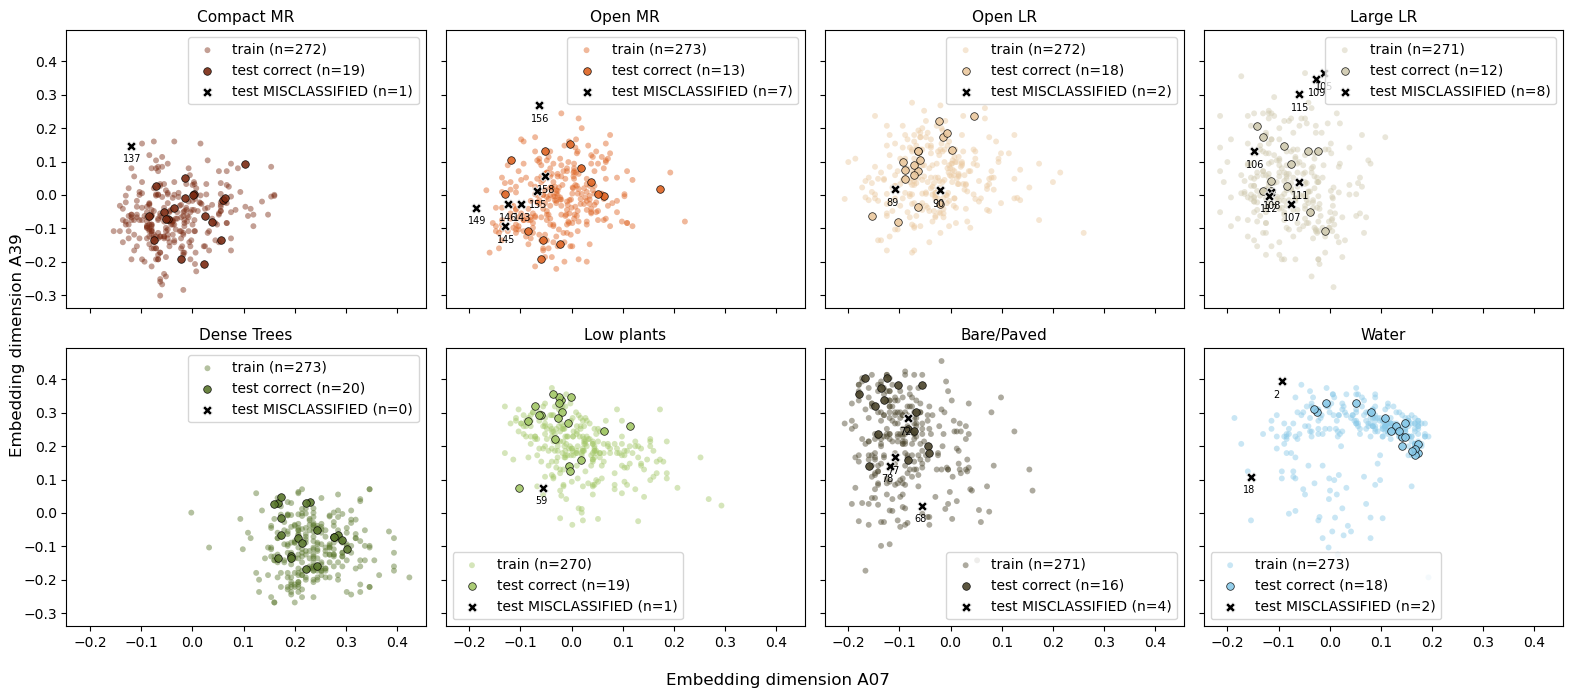

Saved: embedding_scatter_by_class.png, embedding_scatter_overlay.png


In [63]:
"""
Diagnostic: 2D scatter of training + test points in embedding space
=====================================================================

Plots training and test points along TWO chosen embedding dimensions
(e.g. your two most important features from RF feature importance), one
subplot per LCZ class, so you can visually inspect what each class's "blob"
actually looks like: tight and compact vs. spread out vs. possibly
multimodal (two separate sub-clusters).

Train points = light class-colored dots.
Test points, correctly classified   = colored 'o' with black outline.
Test points, MISCLASSIFIED          = solid BLACK 'X', larger, so errors
                                       stand out visually against the blob.

CAVEAT: this is a 2D slice through a 64-dimensional space. Two classes (or
sub-clusters within a class) can look separated here but be entangled in
the other 62 dimensions, or vice versa. Treat this as a sanity-check /
intuition-builder -- for a rigorous, full-dimensional check, see script 06
(multimodality check via k-means).

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- test_centroids   : ee.FeatureCollection, test points, property 'LCZ_class'
- classified       : ee.Image, the classifier's output (predicted class per pixel)
- class_labels     : dict mapping class id -> readable name
- palette          : list of hex colors, in the same order as class_labels
"""

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text

LABEL_PROP = "LCZ_class"
PRED_PROP = "classification"

# EDIT: swap these for your actual most-important bands from feature importance
FEATURE_X = "A07"
FEATURE_Y = "A39"

class_ids_sorted = sorted(class_labels.keys())
class_colors = {cid: palette[i] for i, cid in enumerate(class_ids_sorted)}

# 1. Sample the two chosen bands at train points, and the two bands + predicted
#    class at test points, so we can tell correct from misclassified.
two_band_image = embeddingsImage.select([FEATURE_X, FEATURE_Y])
two_band_with_pred = two_band_image.addBands(classified.rename(PRED_PROP))

train_sample = two_band_image.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=False
)
'''
test_sample = two_band_with_pred.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP], scale=10, geometries=False
)
'''
test_sample = two_band_with_pred.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=False
)

train_df = geemap.ee_to_df(train_sample, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])
test_df = geemap.ee_to_df(test_sample, remove_geom=False)
if "geo" in test_df.columns:
    test_df = test_df.drop(columns=["geo"])

test_df["is_misclassified"] = test_df[PRED_PROP] != test_df[LABEL_PROP]

class_values = sorted(train_df[LABEL_PROP].unique())
n_mis_total = int(test_df["is_misclassified"].sum())
print(f"Plotting {FEATURE_X} vs {FEATURE_Y} for classes:",
      {cv: class_labels.get(cv, cv) for cv in class_values})
print(f"Misclassified test points: {n_mis_total} / {len(test_df)}")
# 2. Grid of subplots, one per class
n = len(class_values)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols,  sharex=True, sharey=True, figsize=(4 * ncols, 3.5 * nrows))
axes = np.array(axes).reshape(-1)

x_all = pd.concat([train_df[FEATURE_X], test_df[FEATURE_X]])
y_all = pd.concat([train_df[FEATURE_Y], test_df[FEATURE_Y]])
pad_x = (x_all.max() - x_all.min()) * 0.05
pad_y = (y_all.max() - y_all.min()) * 0.05
xlim = (x_all.min() - pad_x, x_all.max() + pad_x)
ylim = (y_all.min() - pad_y, y_all.max() + pad_y)


for i, cv in enumerate(class_values):
    ax = axes[i]
    color = class_colors[cv]

    tr = train_df[train_df[LABEL_PROP] == cv]
    te = test_df[test_df[LABEL_PROP] == cv]
    te_correct = te[~te["is_misclassified"]]
    te_mis = te[te["is_misclassified"]]

    ax.scatter(tr[FEATURE_X], tr[FEATURE_Y], c=color, s=18, alpha=0.45,
               edgecolor="none", label=f"train (n={len(tr)})", zorder=1)
    ax.scatter(te_correct[FEATURE_X], te_correct[FEATURE_Y], facecolor=color, edgecolor="black",
               marker="o", s=30, linewidth=0.5, alpha=0.9,
               label=f"test correct (n={len(te_correct)})", zorder=2)
    ax.scatter(te_mis[FEATURE_X], te_mis[FEATURE_Y], facecolor="black", edgecolor="white",
               marker="X", s=50, linewidth=0.6,
               label=f"test MISCLASSIFIED (n={len(te_mis)})", zorder=3)

    
    texts = []
    for _, r in te_mis.iterrows():
        text = ax.annotate(str(int(r['point_id'])), (r[FEATURE_X], r[FEATURE_Y]),
                            fontsize=7, xytext=(-6, -12), textcoords='offset points')
        texts.append(text)
    '''
    if texts:  # adjust_text errors/no-ops on an empty list for some versions
        adjust_text(
            texts,
            ax=ax,
            prevent_crossings=True,
            force_text=(0.3, 0.5),
            arrowprops=dict(arrowstyle="-", color="dimgray", lw=0.6, alpha=0.8,
                             shrinkA=0, shrinkB=2),
        )
    '''
        
    if len(tr) > 0:
        ax.scatter(tr[FEATURE_X].mean(), tr[FEATURE_Y].mean(), c="none", edgecolor="black",
                   marker="+", s=80, linewidth=1, zorder=4)

    ax.set_title(class_labels.get(cv, cv), fontsize=11)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.legend(fontsize=10, loc="best")

    




for j in range(n, len(axes)):
    axes[j].axis("off")

fig.supxlabel(f"Embedding dimension {FEATURE_X}")
fig.supylabel(f"Embedding dimension {FEATURE_Y}")
#fig.suptitle(f"Train / test points per class, in {FEATURE_X}-{FEATURE_Y} space\n"
#             "black X = misclassified test point, black + = training centroid", y=1.02)
plt.tight_layout()
plt.savefig("./images/embedding_scatter_by_class_RFopti1_Gen_Laus.png", dpi=400, bbox_inches="tight", transparent=True)
plt.show()


print("Saved: embedding_scatter_by_class.png, embedding_scatter_overlay.png")


64 embedding bands: ['A00', 'A01', 'A02', 'A03', 'A04'] ...
Classes: {np.int64(1): 'Compact MR', np.int64(2): 'Open MR', np.int64(3): 'Open LR', np.int64(4): 'Large LR', np.int64(5): 'Dense Trees', np.int64(6): 'Low plants', np.int64(7): 'Bare/Paved', np.int64(8): 'Water'}

Intra-class spread in embedding space (training points only):
             n_train  median_dist_to_centroid  mean_dist_to_centroid  \
class                                                                  
Compact MR     272.0                 0.417975               0.440211   
Open MR        273.0                 0.473785               0.486981   
Open LR        272.0                 0.469903               0.497063   
Large LR       271.0                 0.465628               0.480153   
Dense Trees    273.0                 0.509964               0.552063   
Low plants     270.0                 0.541752               0.574530   
Bare/Paved     271.0                 0.575183               0.594471   
Water          

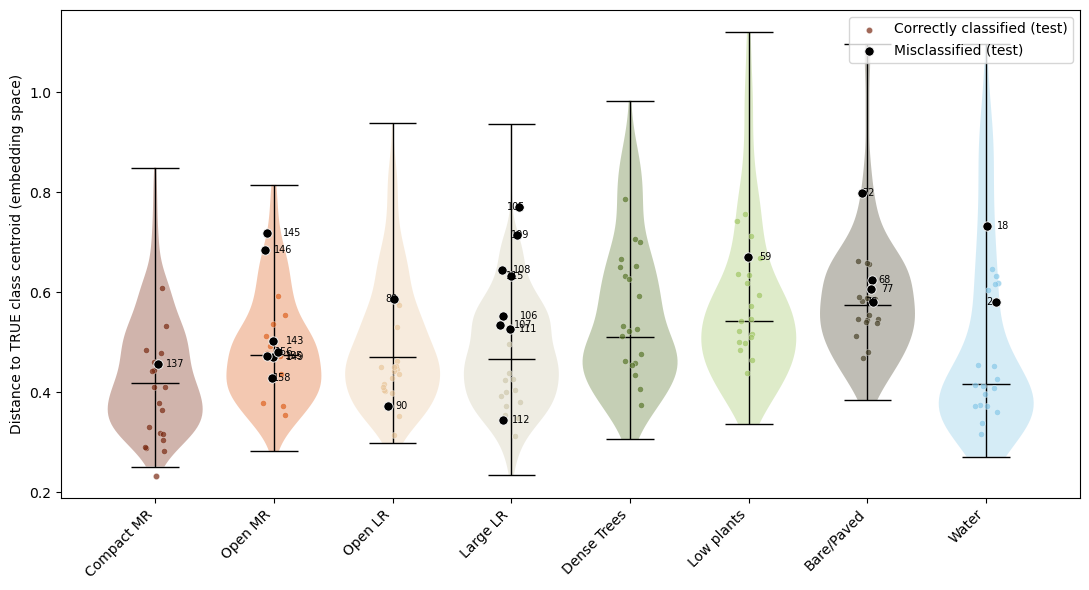

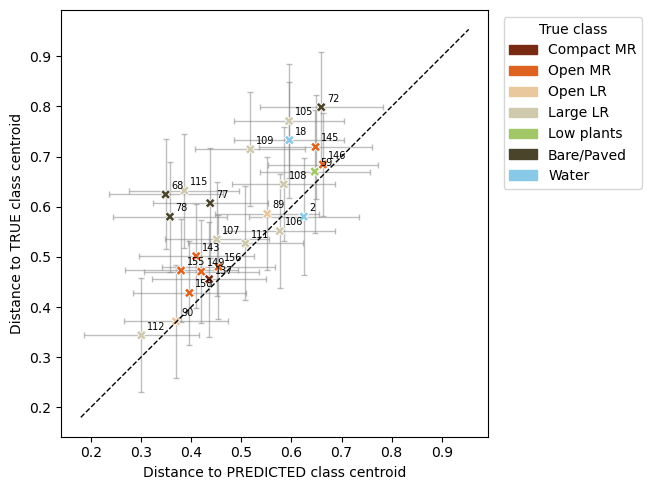

Saved: all_test_embedding_distances.csv, class_intra_class_spread.csv, embedding_intra_class_spread.png, embedding_distance_misclassified.png


In [52]:
"""
Misclassification analysis (4): Embedding-space distance for misclassified points
====================================================================================

For each VALIDATION point (both correct and misclassified), compare its
distance (in 64-dim Alpha Earth embedding space) to:
  (a) the centroid of its TRUE class
  (b) the centroid of its PREDICTED class

This is a *local, per-error* diagnostic -- distinct from the global class-
separability metrics you'd compute pre-training (e.g. Jeffries-Matusita
distance between whole class distributions). Here we're asking, for each
individual mistake: "was this a reasonable confusion given where the point
sits in embedding space, or did the model do something the raw features
don't obviously explain?"

CAVEAT ON THE CENTROID ITSELF: a single mean vector per class assumes each
class is roughly a single, compact blob in embedding space. That may not
hold for classes with high intra-class variance. Alongside the centroid
distance, we also compute each class's INTRA-CLASS SPREAD (how far its own
training points typically sit from its centroid) and use it two ways:
  1. as an uncertainty bar on the plot, sized to that class's typical spread
  2. as a robust z-score, so "distance to centroid" is interpreted relative
     to how tight/loose that class normally is, not as a raw number
Note: the spread metric only tells you the MAGNITUDE of centroid unreliability,
not whether it's one diffuse blob or several separate sub-clusters -- for
that, see the scatter plots (script 05) and the multimodality check (script 06).

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- test_centroids   : ee.FeatureCollection, test points, property 'LCZ_class'
- classified       : ee.Image, the classifier's output (predicted class per pixel)
- class_labels     : dict mapping class id -> readable name, for printing/plots
- palette          : list of hex colors, in the same order as class_labels
                      (class id 1 -> palette[0], id 2 -> palette[1], etc.)
"""

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

LABEL_PROP = "LCZ_class"
PRED_PROP = "classification"

class_ids_sorted = sorted(class_labels.keys())
class_colors = {cid: palette[i] for i, cid in enumerate(class_ids_sorted)}

band_names = embeddingsImage.bandNames()
band_names_list = band_names.getInfo()
print(f"{len(band_names_list)} embedding bands:", band_names_list[:5], "...")

# 1. Attach the 64 embedding bands to the Training and Testing points
training_with_bands = embeddingsImage.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=True
)

# 2. Attach the 64 embedding bands + predicted class to ALL VALIDATION points
#    (no filtering here -- we want correct AND misclassified points)
stacked = embeddingsImage.addBands(classified.rename(PRED_PROP))
'''validation_with_bands = stacked.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP], scale=10, geometries=True
)'''
validation_with_bands = stacked.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=True
)

# 3. Pull ALL training points to pandas, compute per-class centroids + spread
train_df = geemap.ee_to_df(training_with_bands, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])

class_values = sorted(train_df[LABEL_PROP].unique())
print("Classes:", {cv: class_labels.get(cv, cv) for cv in class_values})

centroids = {}
intra_dists = {}  # class -> distances of that class's OWN training points to their centroid
for cv in class_values:
    subset = train_df.loc[train_df[LABEL_PROP] == cv, band_names_list].to_numpy(dtype=float)
    centroid = subset.mean(axis=0)
    centroids[cv] = centroid
    intra_dists[cv] = np.linalg.norm(subset - centroid, axis=1)

spread_stats = {}
for cv in class_values:
    d = intra_dists[cv]
    median_d = float(np.median(d))
    mad = float(np.median(np.abs(d - median_d)))
    robust_sigma = 1.4826 * mad if mad > 0 else float(np.std(d))
    spread_stats[cv] = {
        "n_train": len(d),
        "median_dist_to_centroid": median_d,
        "mean_dist_to_centroid": float(np.mean(d)),
        "robust_sigma": robust_sigma,
        "p25": float(np.percentile(d, 25)),
        "p75": float(np.percentile(d, 75)),
    }

spread_df = pd.DataFrame(spread_stats).T
spread_df.index = spread_df.index.map(lambda c: class_labels.get(c, c))
spread_df.index.name = "class"
print("\nIntra-class spread in embedding space (training points only):")
print(spread_df)

# 4. Pull ALL test/validation points to pandas
test_df = geemap.ee_to_df(validation_with_bands, remove_geom=False)
if "geo" in test_df.columns:
    test_df = test_df.drop(columns=["geo"])
test_df = test_df[band_names_list + [LABEL_PROP, PRED_PROP, "point_id"]].copy()

n_test = len(test_df)
print(f"\nTotal validation points: {n_test}")


# 5. Distances to true/predicted centroids, robust z-scores, rank of true class
#    -- computed for EVERY test point, not just misclassified ones
def compute_distances(row):
    vec = row[band_names_list].to_numpy(dtype=float)
    dists = {cv: float(np.linalg.norm(vec - cen)) for cv, cen in centroids.items()}
    true_cls = row[LABEL_PROP]
    pred_cls = row[PRED_PROP]

    ranked = sorted(dists.items(), key=lambda kv: kv[1])
    rank_of_true = [i for i, (cv, _) in enumerate(ranked, start=1) if cv == true_cls][0]

    dist_true = dists[true_cls]
    dist_pred = dists[pred_cls]
    z_true = (dist_true - spread_stats[true_cls]["median_dist_to_centroid"]) / spread_stats[true_cls]["robust_sigma"]
    z_pred = (dist_pred - spread_stats[pred_cls]["median_dist_to_centroid"]) / spread_stats[pred_cls]["robust_sigma"]

    return pd.Series(
            {
                "dist_to_true_centroid": dist_true,
                "dist_to_pred_centroid": dist_pred,
                "true_class_sigma": spread_stats[true_cls]["robust_sigma"],
                "pred_class_sigma": spread_stats[pred_cls]["robust_sigma"],
                "z_true": z_true,
                "z_pred": z_pred,
                "rank_of_true_class": rank_of_true,
            }
        )
def compute_distances_train(row):
    vec = row[band_names_list].to_numpy(dtype=float)
    dists = {cv: float(np.linalg.norm(vec - cen)) for cv, cen in centroids.items()}
    true_cls = row[LABEL_PROP]

    ranked = sorted(dists.items(), key=lambda kv: kv[1])
    rank_of_true = [i for i, (cv, _) in enumerate(ranked, start=1) if cv == true_cls][0]

    dist_true = dists[true_cls]
    z_true = (dist_true - spread_stats[true_cls]["median_dist_to_centroid"]) / spread_stats[true_cls]["robust_sigma"]

    return pd.Series(
            {
                "dist_to_true_centroid": dist_true,
                "true_class_sigma": spread_stats[true_cls]["robust_sigma"],
                "z_true": z_true,
                "rank_of_true_class": rank_of_true,
            }
        )


train_df = pd.concat([train_df, train_df.apply(compute_distances_train, axis=1)], axis=1)
test_df = pd.concat([test_df, test_df.apply(compute_distances, axis=1)], axis=1)
test_df["is_misclassified"] = test_df[PRED_PROP] != test_df[LABEL_PROP]
test_df["true_name"] = test_df[LABEL_PROP].map(class_labels)
test_df["pred_name"] = test_df[PRED_PROP].map(class_labels)
test_df["ratio_true_over_pred"] = test_df["dist_to_true_centroid"] / test_df["dist_to_pred_centroid"]

n_mis = int(test_df["is_misclassified"].sum())
print(f"Misclassified: {n_mis} / {n_test} ({100 * n_mis / n_test:.1f}%)")

df = test_df[test_df["is_misclassified"]].copy()  # kept for backward compatibility below

print(df[["true_name", "pred_name", "dist_to_true_centroid", "dist_to_pred_centroid", "LCZ_class",
          "z_true", "z_pred", "rank_of_true_class"]].describe())

surprising = df.sort_values("z_true")
print(f"\nMost surprising misclassified points (typical for their TRUE class, "
      "yet still misclassified -- sorted by z_true ascending):")
print(surprising[["true_name", "pred_name", "z_true", "z_pred", "rank_of_true_class"]].head(10))






In [ ]:
# 6a. Violin plot: intra-class spread (from TRAINING points), with ALL test
#     points overlaid at their true class's position -- correctly classified
#     in a light class-colored dot, misclassified in BLACK so they stand out.
present_ids = [cv for cv in class_ids_sorted if cv in class_values]
order_names = [class_labels[cv] for cv in present_ids]
order_colors = [class_colors[cv] for cv in present_ids]

fig, ax = plt.subplots(figsize=(11, 6))
violin_data = [intra_dists[cv] for cv in present_ids]
parts = ax.violinplot(violin_data, showmedians=True, widths=0.8)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor(order_colors[i])
    pc.set_alpha(0.35)
for key in ("cmedians", "cbars", "cmins", "cmaxes"):
    parts[key].set_color("black")
    parts[key].set_linewidth(1)

rng = np.random.default_rng(42)
for i, cv in enumerate(present_ids, start=1):
    subset = test_df[test_df[LABEL_PROP] == cv]

    correct = subset[~subset["is_misclassified"]]
    jitter_c = rng.uniform(-0.1, 0.1, size=len(correct))
    ax.scatter(np.full(len(correct), i) + jitter_c, correct["dist_to_true_centroid"],
               color=order_colors[i - 1], alpha=0.7, s=20, edgecolor="white", linewidth=0.3,
               zorder=2, label="Correctly classified (test)" if i == 1 else None)

    mis = subset[subset["is_misclassified"]]
    jitter_m = rng.uniform(-0.1, 0.1, size=len(mis))
    ax.scatter(np.full(len(mis), i) + jitter_m, mis["dist_to_true_centroid"],
               color="black", s=45, edgecolor="white", linewidth=0.6,
               zorder=3, label="Misclassified (test)" if i == 1 else None)
    for _, r in mis.iterrows():
        ax.annotate(str(int(r['point_id'])), (i + rng.uniform(-0.1, 0.1), r["dist_to_true_centroid"]),
                    fontsize=7, ha='left', va='center', xytext=(3, 0), textcoords='offset points')

ax.set_xticks(range(1, len(present_ids) + 1))
ax.set_xticklabels(order_names, rotation=45, ha="right")
ax.set_ylabel("Distance to TRUE class centroid (embedding space)")
#ax.set_title("Intra-class spread (violin, training points) vs. all validation points\n"
#              "colored dots = correctly classified, black dots = misclassified")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("./images/embedding_violin_intra_class_spread_RFoptiv1_Gen_Laus.png", dpi=400, transparent=True)
plt.show()


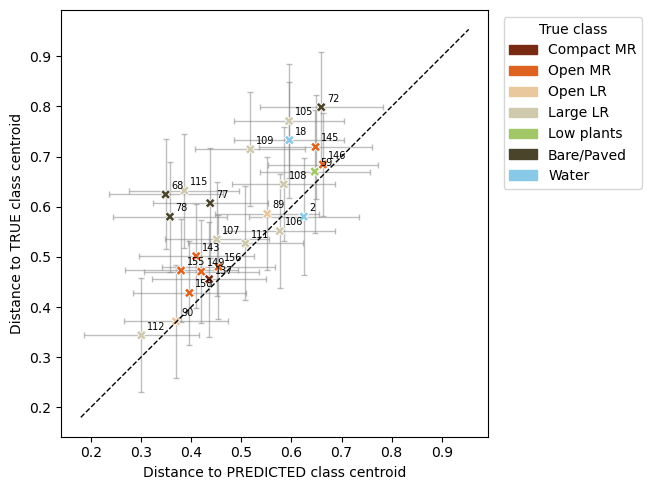

Saved: all_test_embedding_distances.csv, class_intra_class_spread.csv, embedding_intra_class_spread.png, embedding_distance_misclassified.png


In [53]:
# ===============================================================================

# 6b. Scatter: dist to true vs dist to predicted centroid, WITH uncertainty
#     bars. Only meaningful for MISCLASSIFIED points (for correct ones,
#     true==pred so this collapses to a point on the diagonal by definition).
point_colors = df[LABEL_PROP].map(class_colors)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    df["dist_to_pred_centroid"], df["dist_to_true_centroid"],
    xerr=df["pred_class_sigma"], yerr=df["true_class_sigma"],
    fmt="none", ecolor="gray", elinewidth=1, capsize=2, alpha=0.5, zorder=1,
)
ax.scatter(
    df["dist_to_pred_centroid"], df["dist_to_true_centroid"],
    facecolor=point_colors, edgecolor="white",marker="X", s=50, linewidth=0.6,
    
)
for _, r in df.iterrows():
    ax.annotate(str(int(r['point_id'])), (r['dist_to_pred_centroid'], r['dist_to_true_centroid']),
                fontsize=7, xytext=(4, 4), textcoords='offset points')
lims = [0.18, max(
    (df["dist_to_true_centroid"] + df["true_class_sigma"]).max(),
    (df["dist_to_pred_centroid"] + df["pred_class_sigma"]).max(),
) * 1.05]
ax.plot(lims, lims, "k--", lw=1, label="dist_true = dist_pred")
ax.set_xlabel("Distance to PREDICTED class centroid")
ax.set_ylabel("Distance to TRUE class centroid")
ax.set_aspect('equal')
#ax.set_title("Embedding-space distance for MISCLASSIFIED points\n"
#              "error bars = that class's own robust spread (1 sigma); "
#              "below line = point closer to its true class")

present_classes = sorted(df[LABEL_PROP].unique())
handles = [mpatches.Patch(color=class_colors[c], label=class_labels.get(c, c)) for c in present_classes]
ax.legend(handles=handles, title="True class", bbox_to_anchor=(1.02, 1), loc="best")
plt.tight_layout()
plt.savefig("./images/embedding_distance_misclassified_RFopti1_Gen_Laus.png", dpi=400, bbox_inches="tight", transparent=True)
plt.show()

test_df.to_csv("all_test_embedding_distances.csv", index=False)
spread_df.to_csv("class_intra_class_spread.csv")
print("Saved: all_test_embedding_distances.csv, class_intra_class_spread.csv, "
      "embedding_intra_class_spread.png, embedding_distance_misclassified.png")

In [20]:
"""
Diagnostic: rigorous check for multimodal (sub-clustered) classes
=====================================================================

The violin plot (script 04) tells you HOW MUCH a class's training points
spread out around their centroid, but not WHY: a wide violin could mean
(a) one genuinely diffuse blob, or (b) two or more tight sub-clusters with
an empty gap between them -- in which case the single centroid sits
somewhere no real training point actually is. The 2D scatter plots (script
05) give visual intuition but only show 2 of the 64 dimensions at a time,
so they can miss (or fabricate the appearance of) structure that's really
about other dimensions.

This script checks for sub-clustering directly in the FULL 64-dimensional
embedding space, per class, by comparing a single centroid (k=1) against a
2-centroid k-means split (k=2):

- compactness_gain_pct : how much smaller the average distance-to-nearest-
                          centroid becomes when allowing 2 centroids instead
                          of 1. Large gain (e.g. >25-30%) suggests the class
                          isn't well described by one center.
- silhouette_k2        : how well-separated the 2 sub-clusters are
                          (-1 to 1; >0.25 is a weak-but-real split, >0.5 is
                          a clear, well-separated split; near 0 or negative
                          means k=2 isn't finding real structure, it's just
                          cutting a blob in half arbitrarily).
- cluster_balance       : ratio of smaller-to-larger sub-cluster size. Very
                          low values (e.g. 0.05) mean the "split" is really
                          just isolating a handful of outliers, not a
                          genuine second population.

These are heuristic thresholds, not statistical guarantees -- treat flagged
classes as "worth a closer look" (e.g. re-run with k=3, inspect the
sub-cluster members' locations/dates, consider whether the class definition
is too broad), not as an automatic fix.

Requires: scikit-learn (pip install scikit-learn --break-system-packages if missing)

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- class_labels     : dict mapping class id -> readable name
"""

import ee
import geemap
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

LABEL_PROP = "LCZ_class"
RANDOM_STATE = 42
MIN_POINTS_FOR_CHECK = 10  # skip classes with too few points for a meaningful k=2 split

band_names = embeddingsImage.bandNames()
band_names_list = band_names.getInfo()

# 1. Pull training points with full 64-dim embedding to pandas
training_with_bands = embeddingsImage.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP], scale=10, geometries=True
)
train_df = geemap.ee_to_df(training_with_bands, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])

class_values = sorted(train_df[LABEL_PROP].unique())

results = []
for cv in class_values:
    X = train_df.loc[train_df[LABEL_PROP] == cv, band_names_list].to_numpy(dtype=float)
    n = len(X)
    class_name = class_labels.get(cv, cv)

    if n < MIN_POINTS_FOR_CHECK:
        print(f"Skipping {class_name}: only {n} training points (< {MIN_POINTS_FOR_CHECK})")
        continue

    # k=1 baseline: single centroid, average distance to it
    centroid_k1 = X.mean(axis=0)
    dist_k1 = np.linalg.norm(X - centroid_k1, axis=1)
    mean_dist_k1 = dist_k1.mean()

    # k=2: split, average distance to each point's assigned centroid
    km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
    labels_k2 = km.fit_predict(X)
    dist_k2 = np.linalg.norm(X - km.cluster_centers_[labels_k2], axis=1)
    mean_dist_k2 = dist_k2.mean()

    counts = np.bincount(labels_k2)
    cluster_balance = counts.min() / counts.max()

    sil = silhouette_score(X, labels_k2) if n >= 4 else np.nan

    compactness_gain_pct = 100 * (mean_dist_k1 - mean_dist_k2) / mean_dist_k1

    likely_multimodal = (
        (not np.isnan(sil)) and sil > 0.25
        and compactness_gain_pct > 25
        and cluster_balance > 0.1
    )

    results.append({
        "class": class_name,
        "n_train": n,
        "mean_dist_k1": round(mean_dist_k1, 4),
        "mean_dist_k2": round(mean_dist_k2, 4),
        "compactness_gain_pct": round(compactness_gain_pct, 1),
        "silhouette_k2": round(sil, 3) if not np.isnan(sil) else np.nan,
        "cluster_balance": round(cluster_balance, 3),
        "likely_multimodal": likely_multimodal,
    })
summary = pd.DataFrame(results).sort_values("silhouette_k2", ascending=False)
print("\nMultimodality check (k=1 vs k=2 split), per class:")
print(summary.to_string(index=False))

flagged = summary[summary["likely_multimodal"]]
if len(flagged) > 0:
    print(f"\n{len(flagged)} class(es) show evidence of sub-clustering -- "
          "their single centroid may be unreliable:")
    print(flagged["class"].tolist())
else:
    print("\nNo classes strongly flagged as multimodal under current thresholds.")

summary.to_csv("class_multimodality_check.csv", index=False)
print("\nSaved: class_multimodality_check.csv")

    


Multimodality check (k=1 vs k=2 split), per class:
      class  n_train  mean_dist_k1  mean_dist_k2  compactness_gain_pct  silhouette_k2  cluster_balance  likely_multimodal
      Water      273        0.4945        0.3364                  32.0          0.288            0.119               True
Dense Trees      273        0.5521        0.4196                  24.0          0.255            0.182              False
 Low plants      270        0.5745        0.4472                  22.2          0.197            0.178              False
 Compact MR      272        0.4402        0.3323                  24.5          0.194            0.532              False
 Bare/Paved      271        0.5945        0.4955                  16.7          0.156            0.111              False
    Open LR      272        0.4971        0.4058                  18.4          0.155            0.341              False
   Large LR      271        0.4802        0.3922                  18.3          0.136         

In [21]:
print("train_centroids size:", train_centroids.size().getInfo())
print("reference_points size (after exclusion):", reference_points.size().getInfo())

train_centroids size: 2175
reference_points size (after exclusion): 2175


In [7]:


#!pip install seaborn
import seaborn as sns
#!pip install scipy
from scipy.stats import spearmanr

# Extract feature importances from the RF classifier

importance_dict = classifier.explain().getInfo()
importance_series = pd.Series(importance_dict['importance']).sort_values(ascending=False)


# GEE RF importance comes out as a dict {band_name: importance}


fig, ax = plt.subplots(figsize=(12, 4))
importance_series.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Random Forest Feature Importance (64 embedding dims)')
ax.set_xlabel('Embedding dimension')
ax.set_ylabel('Importance')
ax.tick_params(axis='x', labelsize=7)
plt.tight_layout()
plt.savefig('./output/feature_importance.png', dpi=150)
plt.show()



NameError: name 'classifier' is not defined

In [ ]:
# --- Trier les bandes filtrées par importance décroissante ---
importance_filtered_raw = np.array([importance_series.get(b, 0) for b in labels_filtered])
sort_idx = np.argsort(importance_filtered_raw)[::-1]

corr_sorted_imp = corr_filtered[np.ix_(sort_idx, sort_idx)]
labels_sorted_imp = [labels_filtered[i] for i in sort_idx]
importance_sorted = importance_filtered_raw[sort_idx]

# Tick labels combinés : nom de bande + importance en dessous
tick_labels = [f"{b}\n({imp:.3f})" for b, imp in zip(labels_sorted_imp, importance_sorted)]

# --- Plot ---
fig, ax = plt.subplots(figsize=(max(6, len(idx_keep)*0.5),
                                max(5, len(idx_keep)*0.45)))

im = ax.imshow(corr_sorted_imp, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

ax.set_xticks(range(len(tick_labels)))
ax.set_yticks(range(len(tick_labels)))
ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
ax.set_yticklabels(tick_labels, fontsize=7)

# Annoter les cellules au dessus du threshold
for i in range(len(labels_sorted_imp)):
    for j in range(len(labels_sorted_imp)):
        val = corr_sorted_imp[i, j]
        if i != j and abs(val) > threshold:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=6, fontweight='bold',
                    color='white' if abs(val) > 0.85 else 'black')

ax.set_title(f'Correlations |r| > {threshold}, triées par feature importance (décroissant)', fontsize=10)
plt.tight_layout()
plt.savefig('./output/embedding_correlation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
### Pull embedding values to local numpy for correlation
### training is an ee.FeatureCollection — pull it
training_local = training.getInfo()
features = training_local['features']

band_names = embeddingsImage.bandNames().getInfo()
rows = []
for f in features:
    props = f['properties']
    rows.append({b: props.get(b, np.nan) for b in band_names})

df_emb = pd.DataFrame(rows)

# Spearman correlation (robust to non-linearity)
corr_matrix, _ = spearmanr(df_emb.dropna())
corr_df = pd.DataFrame(corr_matrix, index=band_names, columns=band_names)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_df, 
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0,
    ax=ax, cbar_kws={'shrink': 0.6}
)
ax.set_title('Spearman Cross-Correlation of 64 Embedding Dimensions')
ax.tick_params(axis='both', labelsize=6)
plt.tight_layout()
plt.savefig('./output/embedding_correlation.png', dpi=150)
plt.show()

# Flag highly correlated pairs
high_corr = []
for i in range(len(band_names)):
    for j in range(i+1, len(band_names)):
        c = corr_df.iloc[i, j]
        if abs(c) > 0.85:
            high_corr.append((band_names[i], band_names[j], round(c, 3)))
print(f"Highly correlated pairs (|r|>0.85): {len(high_corr)}")
for pair in high_corr[:10]:
    print(pair)

In [ ]:
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
import numpy as np
import matplotlib.pyplot as plt

# --- Compute Spearman correlation ---
corr_matrix, _ = spearmanr(df_emb.dropna())
corr_df = pd.DataFrame(corr_matrix, index=band_names, columns=band_names)

# --- Reorder bands via hierarchical clustering ---
# Convert correlation to distance (1 - |r| so highly correlated = close)
dist = 1 - np.abs(corr_matrix)
linkage_matrix = linkage(dist, method='ward')
order = leaves_list(linkage_matrix)  # reordered indices

corr_reordered = corr_matrix[np.ix_(order, order)]
labels_reordered = [band_names[i] for i in order]

# --- Plot with matplotlib only ---
fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(corr_reordered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

# Ticks
ax.set_xticks(range(len(labels_reordered)))
ax.set_yticks(range(len(labels_reordered)))
ax.set_xticklabels(labels_reordered, rotation=90, fontsize=6)
ax.set_yticklabels(labels_reordered, fontsize=6)

ax.set_title('Embedding cross-correlation (hierarchically sorted)', fontsize=11)
plt.tight_layout()
plt.savefig('./output/embedding_correlation.png', dpi=150)
plt.show()

In [ ]:
# --- Filter to highly correlated bands only ---
threshold = 0.70
corr_abs = np.abs(corr_reordered)  # already hierarchically sorted

# Find bands that have at least one partner above threshold (excluding self)
np.fill_diagonal(corr_abs, 0)
mask = (corr_abs > threshold).any(axis=1)
idx_keep = np.where(mask)[0]

corr_filtered = corr_reordered[np.ix_(idx_keep, idx_keep)]
labels_filtered = [labels_reordered[i] for i in idx_keep]

print(f"Bands with at least one correlation > {threshold}: {len(idx_keep)} / {len(labels_reordered)}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(max(6, len(idx_keep)*0.45),
                                max(5, len(idx_keep)*0.4)))

im = ax.imshow(corr_filtered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

ax.set_xticks(range(len(labels_filtered)))
ax.set_yticks(range(len(labels_filtered)))
ax.set_xticklabels(labels_filtered, rotation=90, fontsize=7)
ax.set_yticklabels(labels_filtered, fontsize=7)

# Annotate cells — bold the ones above threshold
for i in range(len(labels_filtered)):
    for j in range(len(labels_filtered)):
        val = corr_filtered[i, j]
        if i != j and abs(val) > threshold:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=6, fontweight='bold',
                    color='white' if abs(val) > 0.85 else 'black')

ax.set_title(f'Embedding correlations above |r| > {threshold} (hierarchically sorted)', fontsize=10)
plt.tight_layout()
plt.savefig('./output/embedding_correlation_filtered.png', dpi=150)
plt.show()

In [ ]:
n_top = 12

# --- Top N bandes par importance, ordre inversé ---
top_bands = importance_series.sort_values(ascending=False).index[:n_top].tolist()
top_bands_rev = top_bands[::-1]
importance_top_rev = [importance_series[b] for b in top_bands_rev]

# Sous-matrice de corrélation depuis la matrice complète
corr_top_rev = corr_df.loc[top_bands_rev, top_bands_rev].values

tick_labels_top_rev = [f"{b}\n({imp:.3f})" for b, imp in zip(top_bands_rev, importance_top_rev)]

# Masquer le triangle inférieur (on garde le supérieur)
mask_tri = np.triu(np.ones((n_top, n_top), dtype=bool), k=1)
corr_top_masked = np.where(mask_tri, np.nan, corr_top_rev)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(corr_top_masked, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman r')

ax.set_xticks(range(n_top))
ax.set_yticks(range(n_top))
ax.set_xticklabels(tick_labels_top_rev, rotation=90, fontsize=8)
ax.set_yticklabels(tick_labels_top_rev, fontsize=8)

ax.set_xlabel('Embedding band (feature importance)', fontsize=9, loc='right')
#ax.set_ylabel('Embedding band (feature importance)', fontsize=9)

ax.invert_xaxis()

# Annoter triangle supérieur + diagonale
for i in range(n_top):
    for j in range(n_top):
        if j <= i:
            val = corr_top_rev[i, j]
            if i != j:
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=7,
                        fontweight='bold' if abs(val) > threshold else 'normal',
                        color='white' if abs(val) > 0.85 else 'black')

#ax.set_title(f'Corrélations des {n_top} bandes les plus importantes', fontsize=11)
plt.tight_layout()
plt.savefig(f'./output/embedding_correlation_top{n_top}.png', dpi=150, bbox_inches='tight')
plt.show()